# Assignment 8 — Memory Agent

**Objective:** Implement a memory agent that stores and repeats the last user command.

The agent maintains a small memory containing the most recent user command. When asked to repeat the last command, it retrieves that command from memory.

## Basic idea

The agent follows a simple cycle:

**Receive command → Store command in memory → Wait for next command → Retrieve previous command when requested**

Only the **latest command** is stored. When a new normal command arrives, it replaces the previous one.

In [1]:
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time

## Step 1 — Create the memory agent

The `memory` variable stores the last command given by the user.

In [2]:
class MemoryAgent:
    def __init__(self):
        # At the beginning, the agent has no memory
        self.memory = None

    def process_command(self, command):
        command = command.strip()

        if command.lower() in ["repeat", "repeat last", "last command"]:
            if self.memory is None:
                return "There is no previous command in memory."
            return "Last command: " + self.memory

        elif command.lower() in ["clear", "clear memory"]:
            self.memory = None
            return "Memory cleared."

        else:
            # Store the latest user command
            self.memory = command
            return "Command stored in memory."


## Step 2 — Test the memory agent

We can directly test the main operations before starting the interactive chatbot.

In [3]:
agent = MemoryAgent()

print(agent.process_command("Open my assignment file"))
print(agent.process_command("repeat"))

print(agent.process_command("Start the Python program"))
print(agent.process_command("repeat"))

Command stored in memory.
Last command: Open my assignment file
Command stored in memory.
Last command: Start the Python program


## Step 3 — Show the current memory

This cell makes the internal memory visible so that the state of the agent can be checked easily.

In [4]:
print("Current memory:")
print(agent.memory)

Current memory:
Start the Python program


## Step 4 — Visualize the memory state

The memory box represents what the agent currently remembers. It changes whenever a new command is stored.

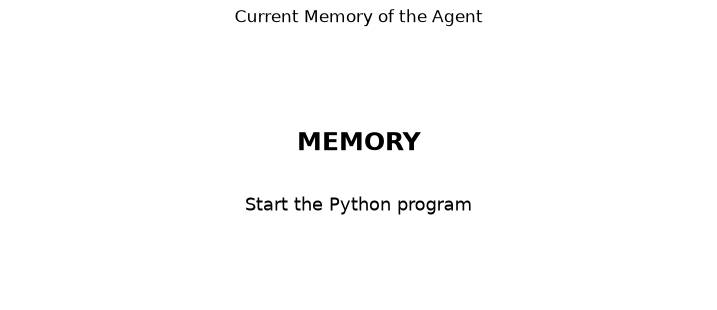

In [5]:
def show_memory(agent, title="Memory Agent"):
    plt.figure(figsize=(9, 3.5))

    plt.text(
        0.5, 0.58,
        "MEMORY",
        ha="center",
        va="center",
        fontsize=18,
        fontweight="bold"
    )

    memory_text = agent.memory if agent.memory is not None else "Empty"

    plt.text(
        0.5, 0.35,
        memory_text,
        ha="center",
        va="center",
        fontsize=13,
        wrap=True
    )

    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.axis("off")
    plt.title(title)
    plt.show()


show_memory(agent, "Current Memory of the Agent")

## Step 5 — Simulate several commands

Here we give the agent a sequence of commands and display how its memory changes after each command.

In [6]:
commands = [
    "Open Google Colab",
    "Run the first cell",
    "Save the notebook",
    "repeat"
]

agent = MemoryAgent()
memory_history = []

for command in commands:
    response = agent.process_command(command)
    memory_history.append(agent.memory)

    print("User:", command)
    print("Agent:", response)
    print("Memory:", agent.memory)
    print("-" * 45)

User: Open Google Colab
Agent: Command stored in memory.
Memory: Open Google Colab
---------------------------------------------
User: Run the first cell
Agent: Command stored in memory.
Memory: Run the first cell
---------------------------------------------
User: Save the notebook
Agent: Command stored in memory.
Memory: Save the notebook
---------------------------------------------
User: repeat
Agent: Last command: Save the notebook
Memory: Save the notebook
---------------------------------------------


## Step 6 — Visualize memory changes

Each point represents the command stored in memory after a user input.

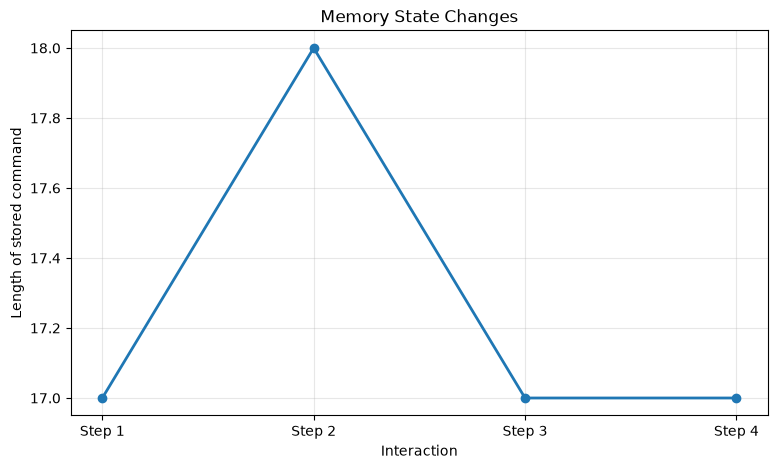

In [7]:
labels = ["Step 1", "Step 2", "Step 3", "Step 4"]
memory_lengths = [len(item) if item else 0 for item in memory_history]

plt.figure(figsize=(9, 5))
plt.plot(labels, memory_lengths, marker="o", linewidth=2)
plt.xlabel("Interaction")
plt.ylabel("Length of stored command")
plt.title("Memory State Changes")
plt.grid(True, alpha=0.3)
plt.show()

## Step 7 — Interactive memory agent

Type normal commands to store them. Type `repeat` to retrieve the previous command. Type `clear` to remove the stored command. Type `exit` to stop the program.

In [8]:
def run_memory_agent():
    agent = MemoryAgent()

    print("Memory Agent started!")
    print("Type a command to store it.")
    print("Type 'repeat' to repeat the last command.")
    print("Type 'clear' to clear memory.")
    print("Type 'exit' to stop.\n")

    while True:
        command = input("You: ")

        if command.lower().strip() == "exit":
            print("Agent: Goodbye!")
            break

        response = agent.process_command(command)
        print("Agent:", response)
        print("Memory:", agent.memory)


run_memory_agent()

Memory Agent started!
Type a command to store it.
Type 'repeat' to repeat the last command.
Type 'clear' to clear memory.
Type 'exit' to stop.

Agent: Command stored in memory.
Memory: go to gym
Agent: Goodbye!


## Step 8 — Small demonstration animation

This shows the memory being updated as different commands arrive.

In [9]:
demo_commands = [
    "Check my email",
    "Open the project",
    "Run the program",
    "repeat"
]

agent = MemoryAgent()

for command in demo_commands:
    response = agent.process_command(command)

    clear_output(wait=True)

    print("User:", command)
    print("Agent:", response)
    print()

    show_memory(agent, "Memory Agent — Current State")
    time.sleep(1.2)

clear_output(wait=True)
print("Demonstration completed.")
print("Final memory:", agent.memory)

Demonstration completed.
Final memory: Run the program


## Final result

The agent successfully stores the latest user command and can retrieve it when the user asks to repeat it. The memory can also be cleared when required.

In [10]:
agent = MemoryAgent()

agent.process_command("Complete assignment 8")
result = agent.process_command("repeat")

print("Memory Agent Test")
print("-----------------")
print("Stored command:", agent.memory)
print("Repeat result:", result)
print("Memory working correctly:", agent.memory == "Complete assignment 8")

Memory Agent Test
-----------------
Stored command: Complete assignment 8
Repeat result: Last command: Complete assignment 8
Memory working correctly: True
